# Random Forest — Original/Masked Color hiperparametre optimizasyonu

**Ortak protokol:** 10.015 HAM10000 görüntüsü, 439 renk özelliği; aynı stratified train/validation/test indeksleri (`random_state=42`). Eğitim üzerinde 3-fold `RandomizedSearchCV` ve **Macro F1** optimizasyonu. Validation yalnızca model seçimi ve karşılaştırma için; **test kullanılmaz**. Original ve Masked ayrı ayrı aranır. `StandardScaler` gerektiğinde CV içinde `Pipeline` kullanılır.

**Dikkat:** Masked sonuçlar gerçek maske kullandığından, gerçek kullanımda otomatik segmentasyon gerekir. Aynı lezyona ait tekrar görüntüler bulunuyorsa bu image-level split veri sızıntısı yaratabilir; metadata ile grup bazlı bölmeyi ayrıca ele almak gerekir.

## 1 — Yollar, özellikler ve ortak veri bölmesi

In [1]:
from pathlib import Path
import sys, json, time
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix
from joblib import dump

CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
if str(PROJECT_ROOT) not in sys.path: sys.path.insert(0, str(PROJECT_ROOT))
from src.config import BASE_DIR
from src.data_loader import load_dataset
FEATURE_DIR = BASE_DIR / "outputs" / "features"
RESULT_DIR = BASE_DIR / "outputs" / "models" / "color_optimized"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

X_sources = {
    "original": FEATURE_DIR / "X_original_color_300x225.npy",
    "masked": FEATURE_DIR / "X_masked_color_300x225.npy",
}
y = np.load(FEATURE_DIR / "y_labels_color_300x225.npy", allow_pickle=False)
ids = np.load(FEATURE_DIR / "image_ids_color_300x225.npy", allow_pickle=False)
df = load_dataset(require_masks=True).reset_index(drop=True)
assert np.array_equal(ids.astype(str), df["image"].to_numpy(dtype=str)), "Görüntü ID sıralaması uyuşmuyor"
assert np.array_equal(y.astype(str), df["label"].to_numpy(dtype=str)), "Etiket sıralaması uyuşmuyor"
for variant, path in X_sources.items():
    if not path.exists(): raise FileNotFoundError(f"Önce color features notebook'unu çalıştır: {path}")
    tmp = np.load(path, mmap_mode="r", allow_pickle=False)
    assert tmp.shape == (len(y), 439), (variant, tmp.shape)
    assert np.issubdtype(tmp.dtype, np.number)

idx = np.arange(len(y))
dev_idx, test_idx = train_test_split(idx, test_size=0.15, random_state=42, stratify=y)
train_idx, val_idx = train_test_split(dev_idx, test_size=0.15/0.85, random_state=42, stratify=y[dev_idx])
assert len(set(train_idx)&set(val_idx)) == len(set(train_idx)&set(test_idx)) == len(set(val_idx)&set(test_idx)) == 0
classes = np.unique(y)
print('Train:',len(train_idx),'Validation:',len(val_idx),'Test (dokunulmayacak):',len(test_idx))
print('Çıktı:',RESULT_DIR)

Train: 7009 Validation: 1503 Test (dokunulmayacak): 1503
Çıktı: C:\Users\Deniz TOZAN\OneDrive - Analythinx Bilişim Hizmetleri Ticaret Anonim Şirketi\WORK\Calismalar\uygulama\Kodlar\Health\outputs\models\color_optimized


## 2 — Model ve hiperparametre uzayı

In [2]:
from sklearn.ensemble import RandomForestClassifier

MODEL_NAME = 'Random_Forest'
base_model = RandomForestClassifier(random_state=42, n_jobs=2)
param_space = {"n_estimators": [100, 200, 350], "max_depth": [None, 8, 12, 18, 25], "min_samples_leaf": [1, 2, 3, 5, 10], "min_samples_split": [2, 5, 10], "max_features": ["sqrt", 0.3, 0.6], "class_weight": [None, "balanced", "balanced_subsample"]}
N_ITER = 18
CV_FOLDS = 3
SEARCH_JOBS = 2  # RAM / işlemci kullanımına göre 1 yapabilirsiniz
print(base_model)
print(param_space)

RandomForestClassifier(n_jobs=2, random_state=42)
{'n_estimators': [100, 200, 350], 'max_depth': [None, 8, 12, 18, 25], 'min_samples_leaf': [1, 2, 3, 5, 10], 'min_samples_split': [2, 5, 10], 'max_features': ['sqrt', 0.3, 0.6], 'class_weight': [None, 'balanced', 'balanced_subsample']}


## 3 — Original ve Masked için ayrı optimizasyon ve validation
İlk çalıştırmada her iki model aranır. Önceden kaydedilmiş çıktıları tekrar üretmek istiyorsanız hücreyi yeniden çalıştırın. Sonuçlar önceki aynı adlı dosyaların üzerine yazılır.

In [3]:
rows=[]
cv=StratifiedKFold(n_splits=CV_FOLDS,shuffle=True,random_state=42)
for variant, path in X_sources.items():
    t0=time.time()
    X=np.load(path, mmap_mode="r", allow_pickle=False)
    X_train=np.asarray(X[train_idx], dtype=np.float32)
    X_val=np.asarray(X[val_idx], dtype=np.float32)
    if not np.isfinite(X_train).all() or not np.isfinite(X_val).all():
        raise ValueError(f"{variant}: NaN/Inf var")
    print(f"\n=== {MODEL_NAME}: {variant} ===",flush=True)
    search=RandomizedSearchCV(
        estimator=base_model,param_distributions=param_space,n_iter=N_ITER,
        scoring="f1_macro",cv=cv,refit=True,n_jobs=SEARCH_JOBS,
        random_state=42,verbose=1,return_train_score=False,error_score="raise"
    )
    search.fit(X_train,y[train_idx])
    pred=search.best_estimator_.predict(X_val)
    train_pred=search.best_estimator_.predict(X_train)
    r={
        "Model":MODEL_NAME,"Variant":variant,"CV_Macro_F1":float(search.best_score_),
        "Train_Macro_F1":float(f1_score(y[train_idx],train_pred,average="macro",zero_division=0)),
        "Val_Accuracy":float(accuracy_score(y[val_idx],pred)),
        "Val_Macro_F1":float(f1_score(y[val_idx],pred,average="macro",zero_division=0)),
        "Val_Macro_Precision":float(precision_score(y[val_idx],pred,average="macro",zero_division=0)),
        "Val_Macro_Recall":float(recall_score(y[val_idx],pred,average="macro",zero_division=0)),
        "MEL_Recall":float(recall_score(y[val_idx],pred,labels=["MEL"],average="macro",zero_division=0)),
        "MEL_Precision":float(precision_score(y[val_idx],pred,labels=["MEL"],average="macro",zero_division=0)),
        "Predicted_Classes":int(len(np.unique(pred))),"Best_Params":json.dumps(search.best_params_,ensure_ascii=False),
        "Search_Seconds":round(time.time()-t0,1),"Train_N":len(train_idx),"Val_N":len(val_idx),"Test_N":len(test_idx),
    }
    rows.append(r)
    prefix=RESULT_DIR/f"{MODEL_NAME}_{variant}"
    pd.DataFrame(search.cv_results_).to_csv(str(prefix)+"_cv_results.csv",index=False)
    pd.DataFrame({"image_id":ids[val_idx],"actual":y[val_idx],"predicted":pred}).to_csv(str(prefix)+"_val_predictions.csv",index=False)
    pd.DataFrame(confusion_matrix(y[val_idx],pred,labels=classes),index=classes,columns=classes).to_csv(str(prefix)+"_confusion_matrix.csv")
    dump(search.best_estimator_,str(prefix)+"_model.joblib")
    print('En iyi CV Macro F1:',round(search.best_score_,4),'Validation Macro F1:',round(r['Val_Macro_F1'],4))
    print('Parametreler:',search.best_params_)
    print(classification_report(y[val_idx],pred,labels=classes,zero_division=0))
    del X_train,X_val,search
summary=pd.DataFrame(rows).sort_values("Val_Macro_F1",ascending=False)
summary.to_csv(RESULT_DIR/f"{MODEL_NAME}_summary.csv",index=False)
display(summary)
print('Test seti kullanılmadı.')


=== Random_Forest: original ===
Fitting 3 folds for each of 18 candidates, totalling 54 fits
En iyi CV Macro F1: 0.469 Validation Macro F1: 0.4606
Parametreler: {'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': 25, 'class_weight': 'balanced'}
              precision    recall  f1-score   support

       AKIEC       0.44      0.39      0.41        49
         BCC       0.45      0.60      0.51        77
         BKL       0.45      0.47      0.46       165
          DF       0.33      0.06      0.10        18
         MEL       0.44      0.50      0.47       167
          NV       0.88      0.86      0.87      1006
        VASC       0.67      0.29      0.40        21

    accuracy                           0.73      1503
   macro avg       0.52      0.45      0.46      1503
weighted avg       0.74      0.73      0.73      1503


=== Random_Forest: masked ===
Fitting 3 folds for each of 18 candidates, totalling 54 fits
En iyi CV Mac

,Model,Variant,CV_Macro_F1,Train_Macro_F1,Val_Accuracy,Val_Macro_F1,Val_Macro_Precision,Val_Macro_Recall,MEL_Recall,MEL_Precision,Predicted_Classes,Best_Params,Search_Seconds,Train_N,Val_N,Test_N
1,Random_Forest,masked,0.495896,0.930806,0.739188,0.529634,0.542981,0.548506,0.520958,0.527273,7,"{""n_estimators"": 200, ""min_samples_split"": 10,...",420.3,7009,1503,1503
0,Random_Forest,original,0.469018,0.961206,0.730539,0.460577,0.523743,0.451571,0.502994,0.444444,7,"{""n_estimators"": 200, ""min_samples_split"": 10,...",616.1,7009,1503,1503


Test seti kullanılmadı.


## 4 — Çıktılar
`outputs/models/color_optimized/` altında model başına **özet CSV**, her varyant için **CV sonuçları, validation tahminleri, confusion matrix ve `.joblib` model** kaydedilir. Önce dört model notebook’unu çalıştırın; ardından değerlendirme notebook’unu açın.

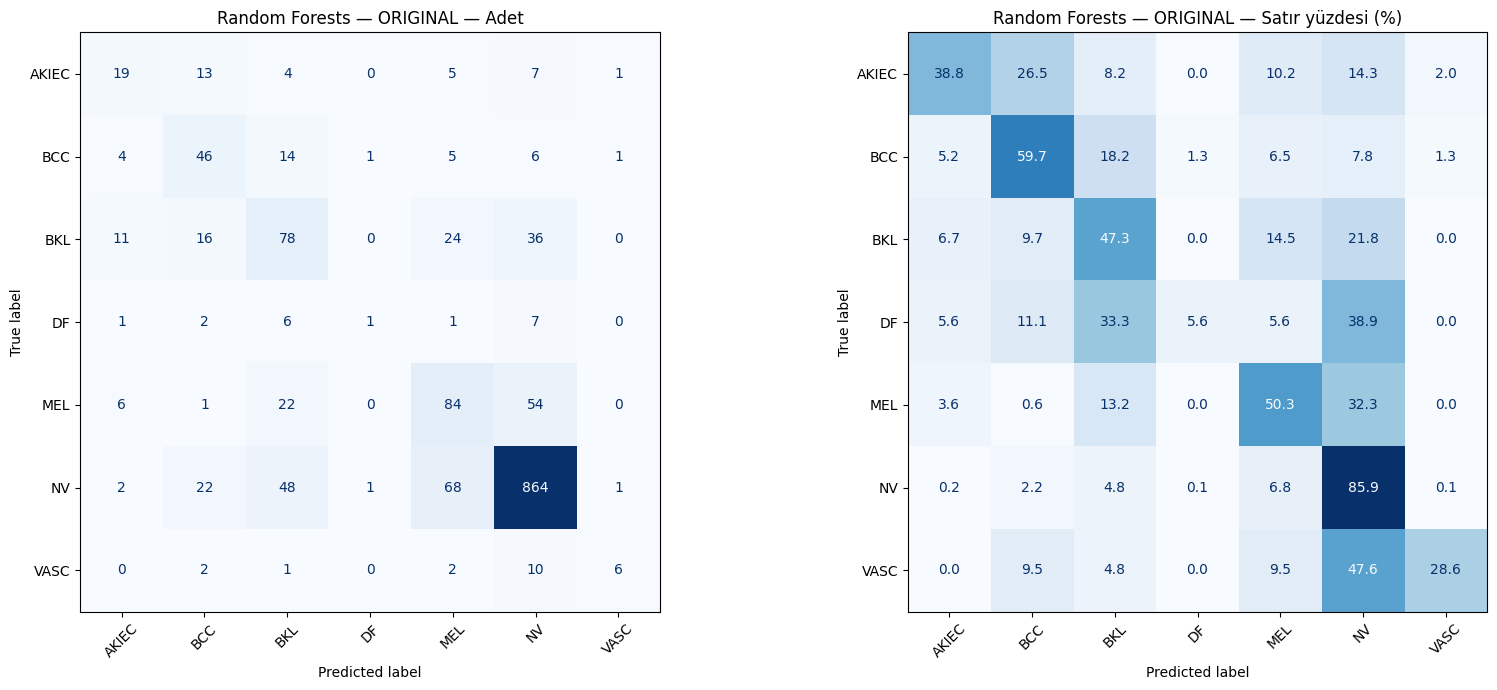


ORIGINAL — Sınıf bazında Recall
Class  Recall (%)
AKIEC       38.78
  BCC       59.74
  BKL       47.27
   DF        5.56
  MEL       50.30
   NV       85.88
 VASC       28.57


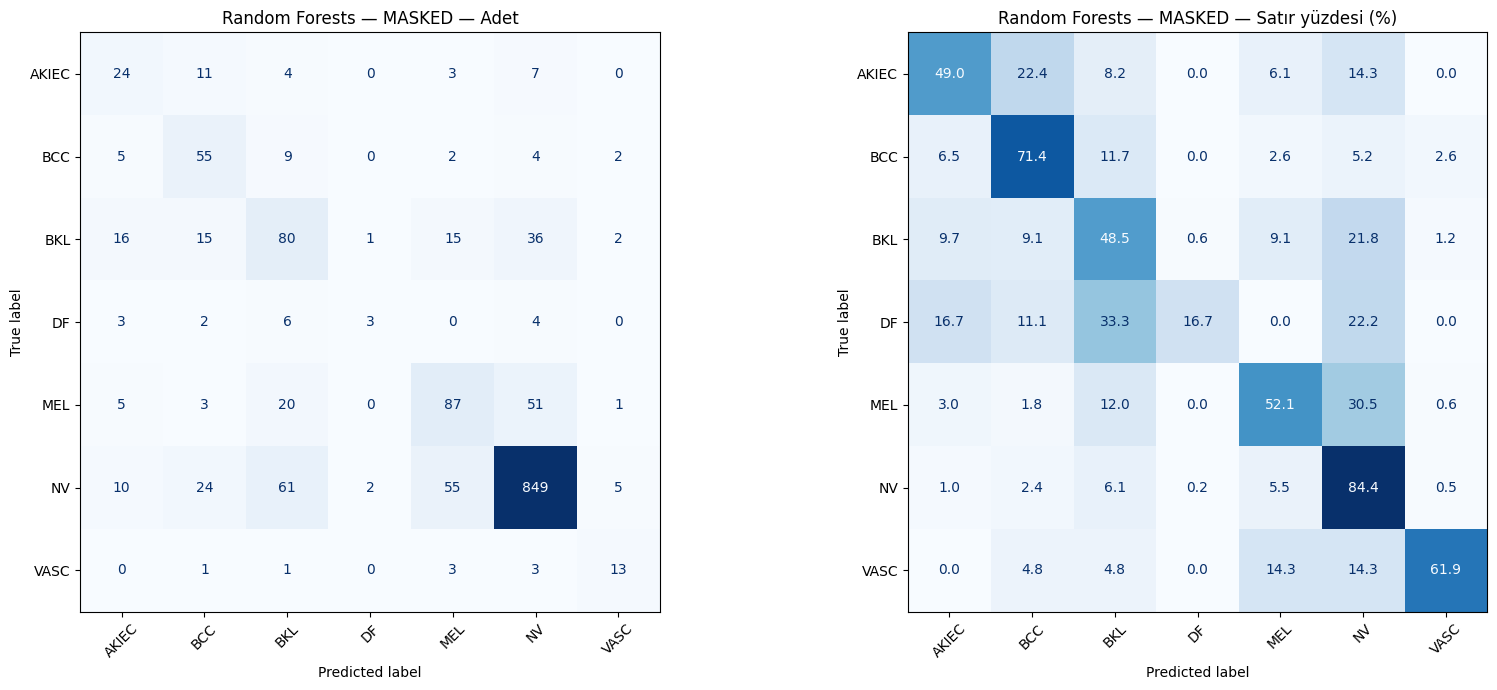


MASKED — Sınıf bazında Recall
Class  Recall (%)
AKIEC       48.98
  BCC       71.43
  BKL       48.48
   DF       16.67
  MEL       52.10
   NV       84.39
 VASC       61.90


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import ConfusionMatrixDisplay

# Proje ve sonuç klasörü
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULT_DIR = ROOT / "outputs" / "models" / "color_optimized"

CLASSES = ["AKIEC", "BCC", "BKL", "DF", "MEL", "NV", "VASC"]

def plot_saved_confusion_matrix(feature_type):

    file_path = (
        RESULT_DIR /
        f"Random_Forest_{feature_type}_confusion_matrix.csv"
    )

    if not file_path.exists():
        raise FileNotFoundError(f"Dosya bulunamadı: {file_path}")

    # Kaydedilmiş confusion matrix
    rf_df = pd.read_csv(file_path, index_col=0)

    # Sınıf sıralamasını sabitle
    rf = rf_df.loc[CLASSES, CLASSES].to_numpy(dtype=int)

    # Her gerçek sınıf için yüzde hesapla
    row_totals = rf.sum(axis=1, keepdims=True)

    rf_pct = np.divide(
        rf,
        row_totals,
        out=np.zeros_like(rf, dtype=float),
        where=row_totals != 0
    ) * 100

    fig, axes = plt.subplots(1, 2, figsize=(17, 7))

    for ax, matrix, fmt, title in zip(
        axes,
        [rf, rf_pct],
        ["d", ".1f"],
        ["Adet", "Satır yüzdesi (%)"]
    ):
        ConfusionMatrixDisplay(
            confusion_matrix=matrix,
            display_labels=CLASSES
        ).plot(
            ax=ax,
            cmap="Blues",
            values_format=fmt,
            colorbar=False
        )

        ax.set_title(f"Random Forests — {feature_type.upper()} — {title}")
        ax.tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.show()

    # Sınıf bazında Recall
    recall = np.divide(
        np.diag(rf),
        rf.sum(axis=1),
        out=np.zeros(len(CLASSES), dtype=float),
        where=rf.sum(axis=1) != 0
    )

    print(f"\n{feature_type.upper()} — Sınıf bazında Recall")
    print(
        pd.DataFrame({
            "Class": CLASSES,
            "Recall (%)": np.round(recall * 100, 2)
        }).to_string(index=False)
    )


# Original Color
plot_saved_confusion_matrix("original")

# Masked Color
plot_saved_confusion_matrix("masked")